# Imports

In [1]:
import os

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

import ts_ucf

# Load and scale data

In [2]:
notebooks_dir = os.path.abspath("")
data_dir = os.path.join(os.path.dirname(notebooks_dir), "data", "mTSBench", "GutenTAG")

In [3]:
data_train = pd.read_csv(os.path.join(data_dir, "GutenTAG_28_train.csv")).iloc[:, 1:-1]
data_test = pd.read_csv(os.path.join(data_dir, "GutenTAG_28_test.csv")).iloc[:, 1:]
labels_test = data_test.pop("is_anomaly")

In [4]:
scaler = MinMaxScaler((-1, 1))
scaled_data_train = scaler.fit_transform(data_train)
scaled_data_test = scaler.transform(data_test)

## Show data

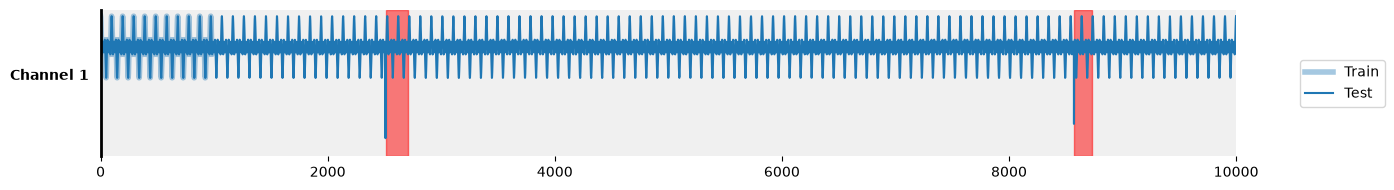

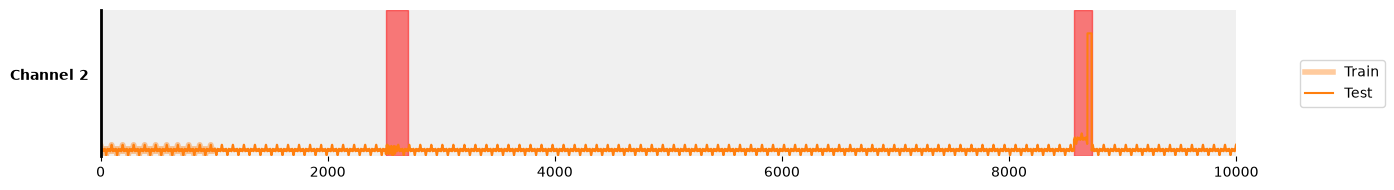

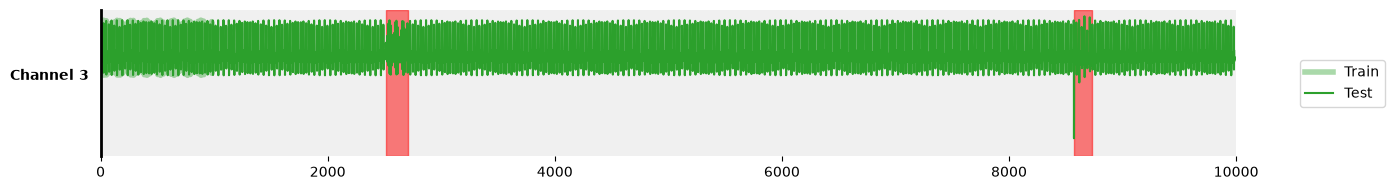

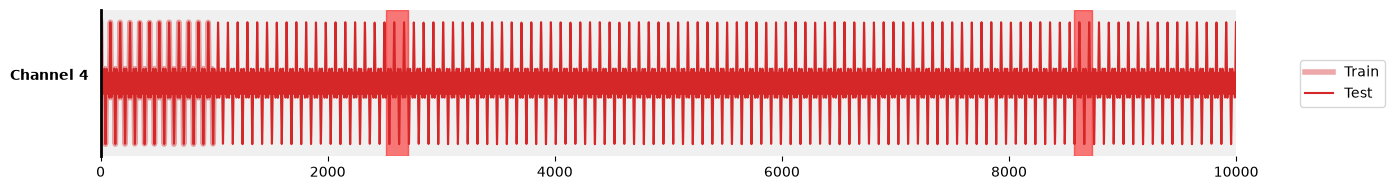

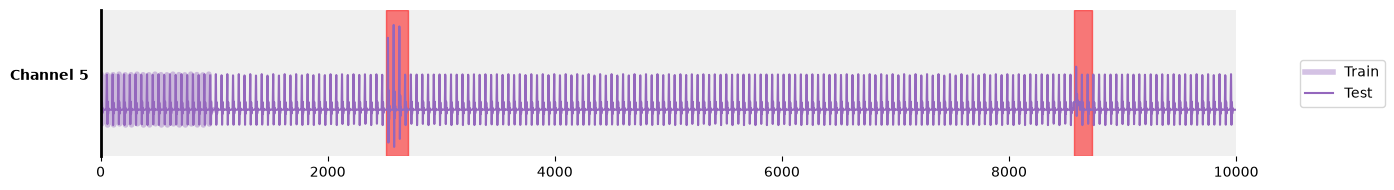

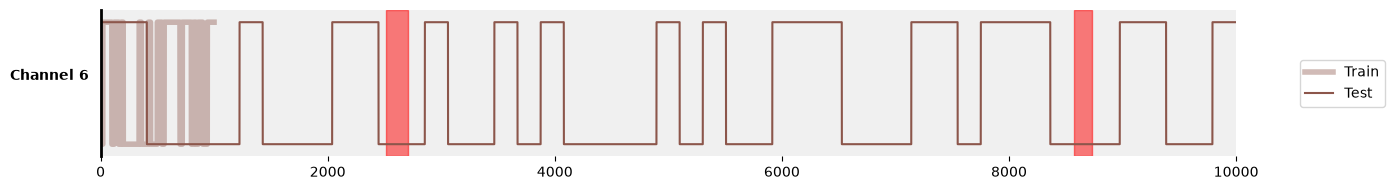

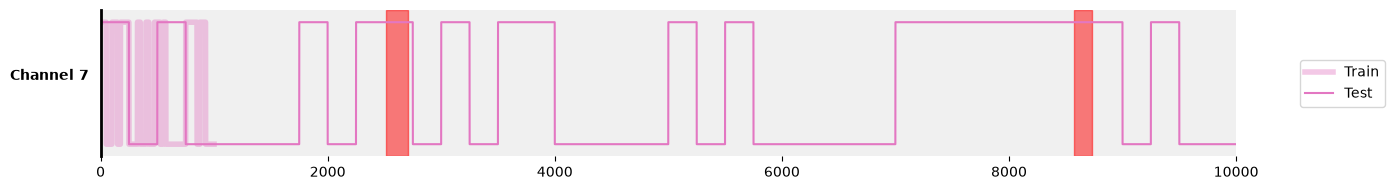

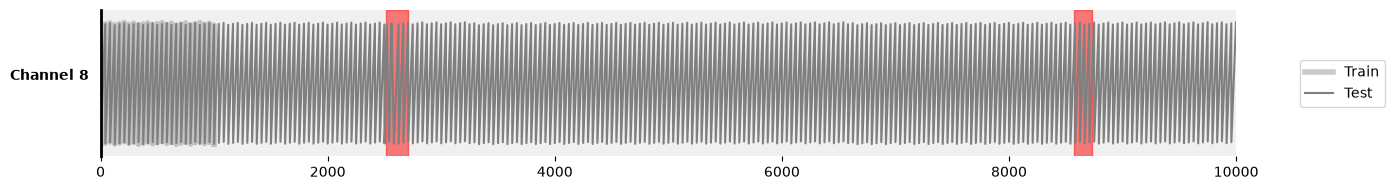

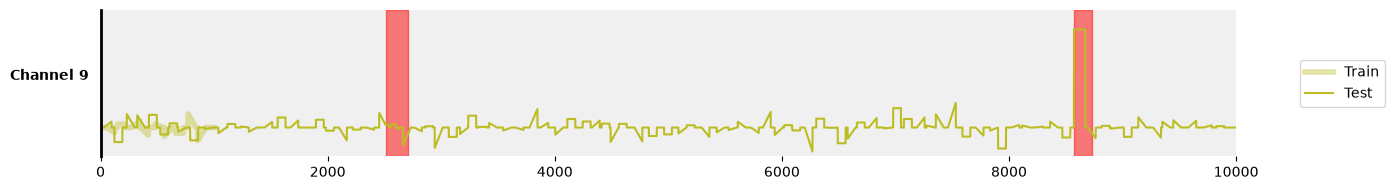

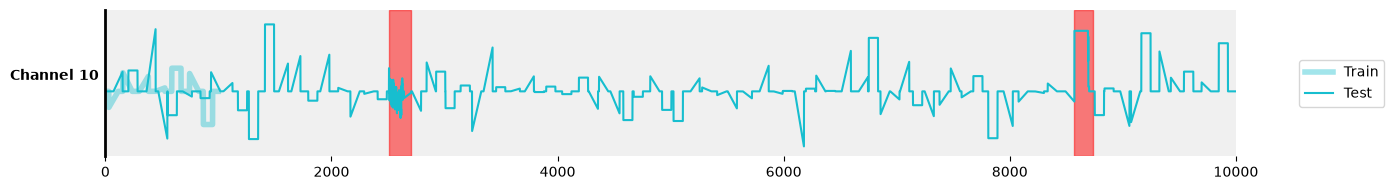

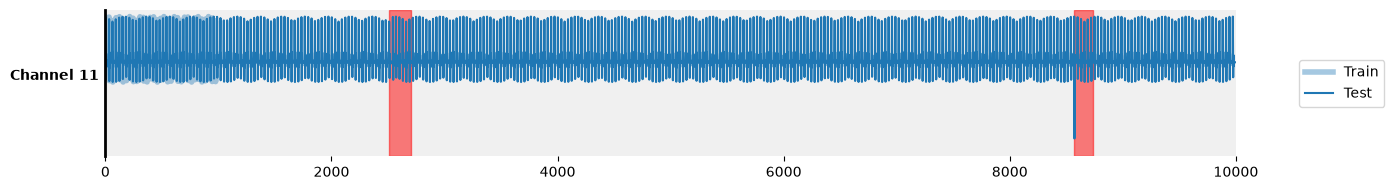

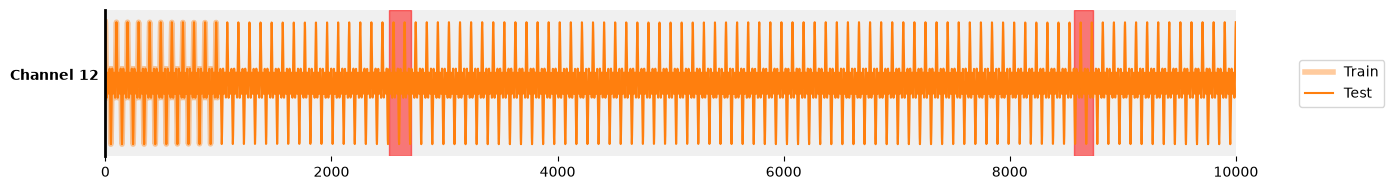

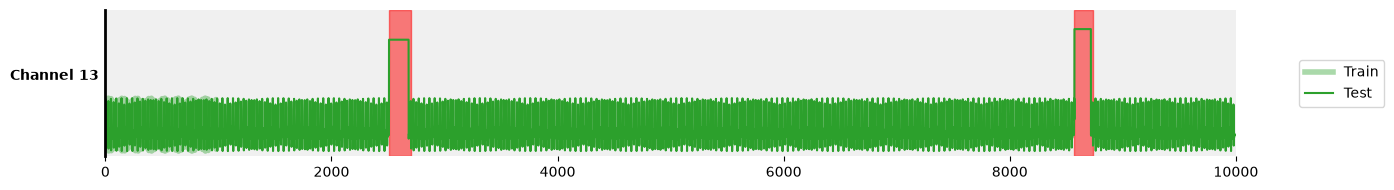

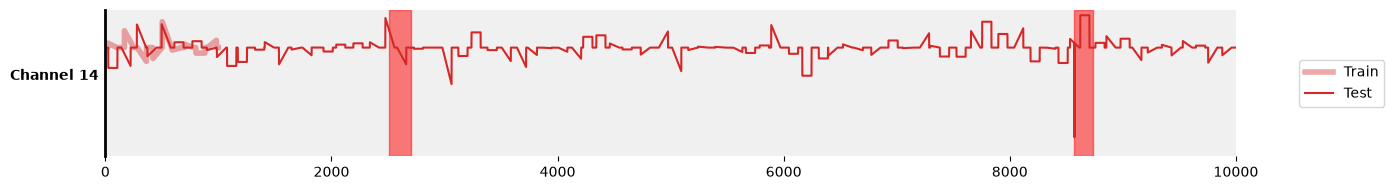

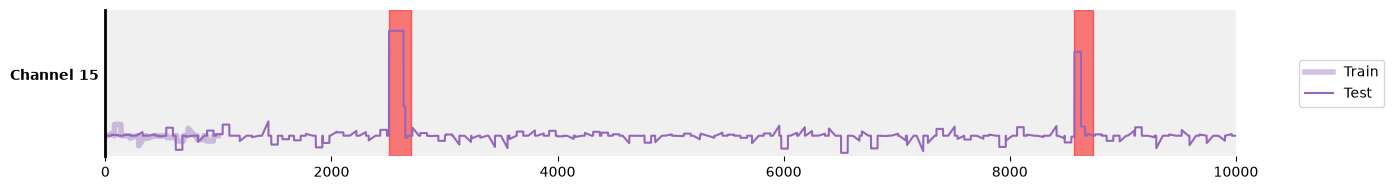

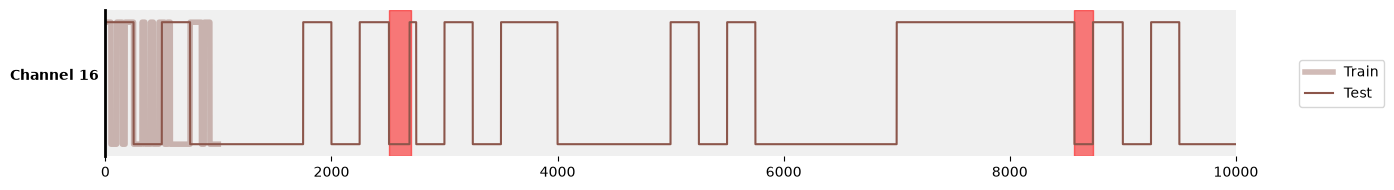

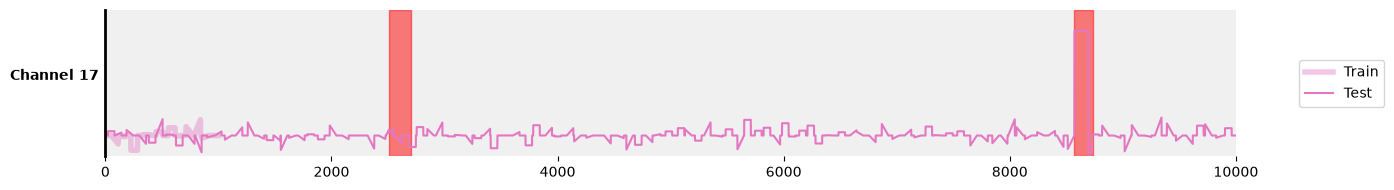

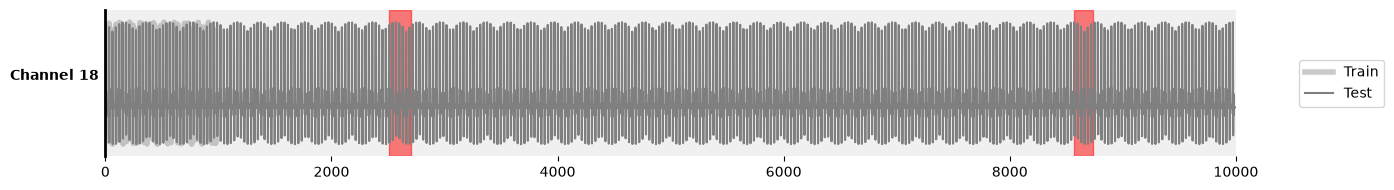

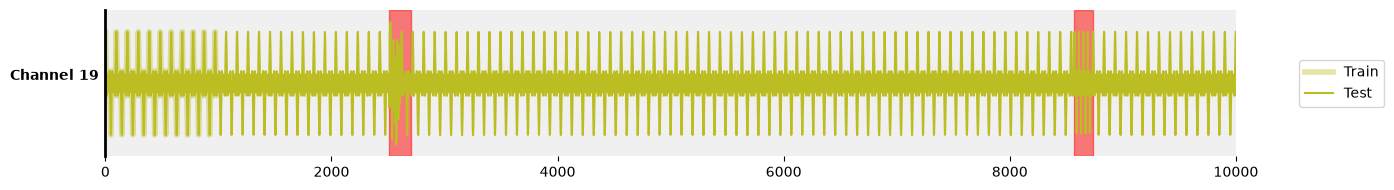

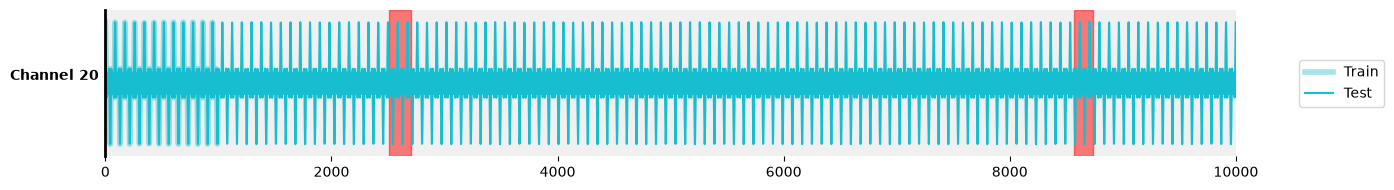

In [5]:
ts_ucf.plots.plot_signals(scaled_data_train, scaled_data_test, point_labels=labels_test)

# Detector

## Infer window size

In [6]:
ws_opt = ts_ucf.core.infer_window_size(scaled_data_train)
ws_opt

17

# Create detector and fit it

In [7]:
detector = ts_ucf.TS_UCF(n_min=1, n_max=10, L=ws_opt, keep_internals=True)

In [8]:
detector.fit(scaled_data_train)

,n_max,10
,L,17
,s,17
,keep_internals,True
,n_min,1


## Compute scores and make them point by point

In [9]:
scores = detector.decision_function(scaled_data_test)
scores.shape # 20 univarite and 1 multivarite score for 588 windows for 10 degrees

(21, 588, 10)

In [10]:
def get_padded_res(res, L, N):
    point_res = np.repeat(res, L)
    padding_length = N - len(point_res)
    return np.pad(point_res, (0, padding_length), mode="edge")

In [11]:
padded_point_scores = get_padded_res(scores[-1, :, 1], detector.L, len(scaled_data_test)) # Take the multivariate results for degree 2

## Plot the scores

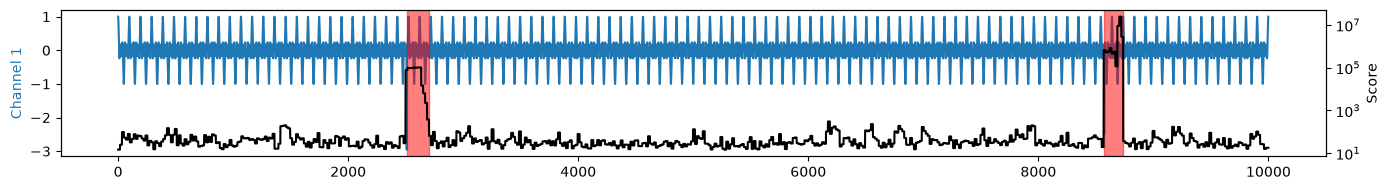

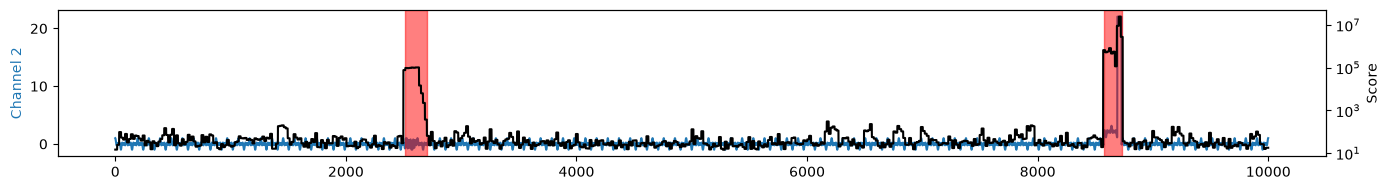

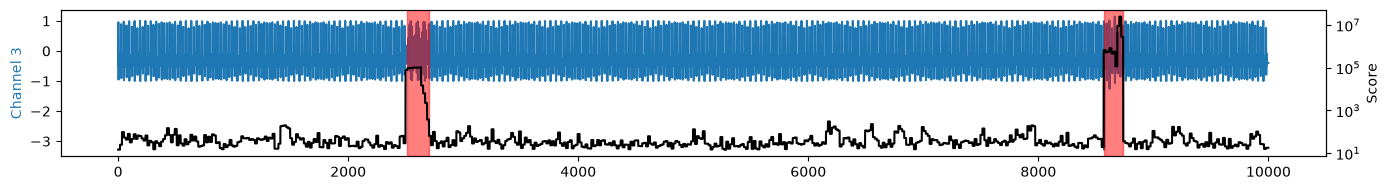

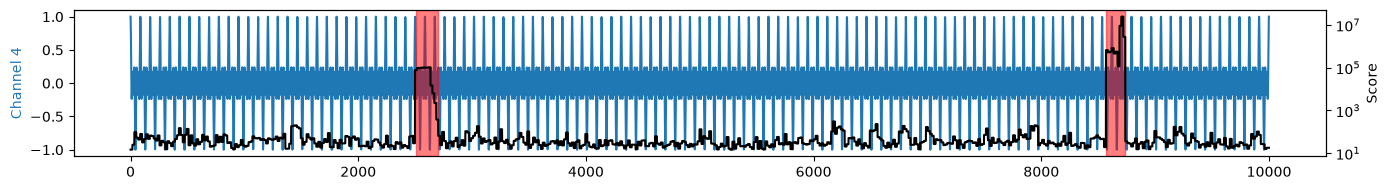

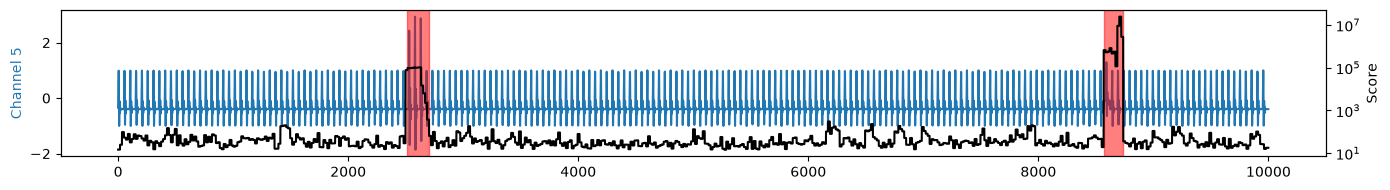

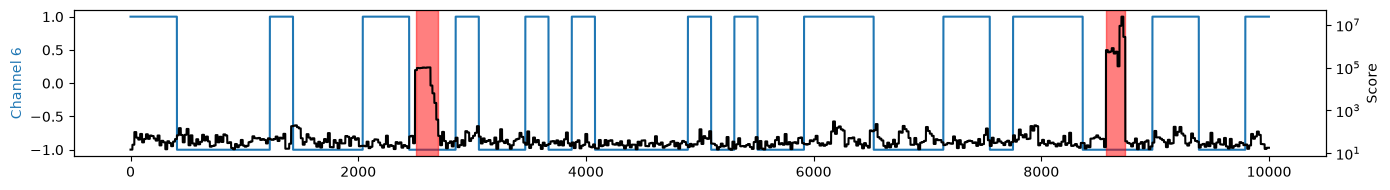

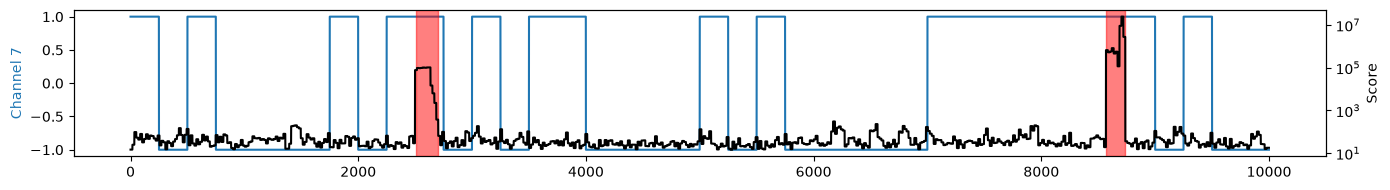

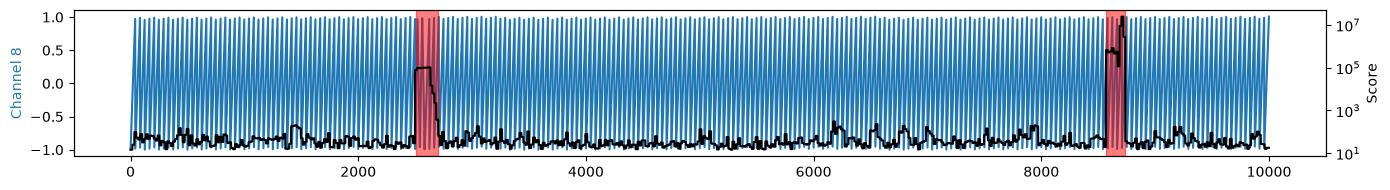

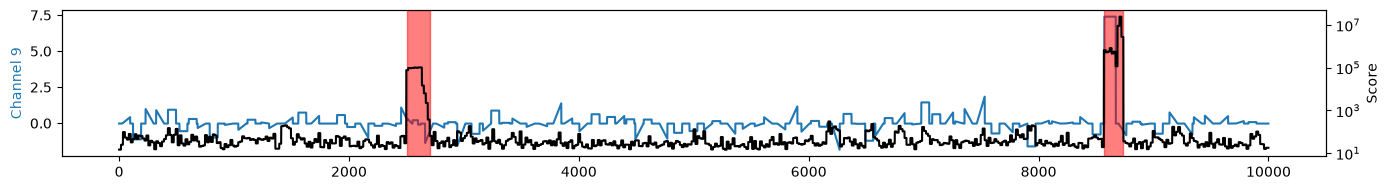

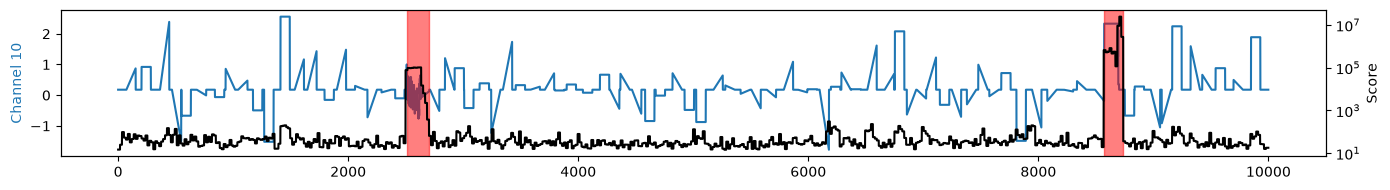

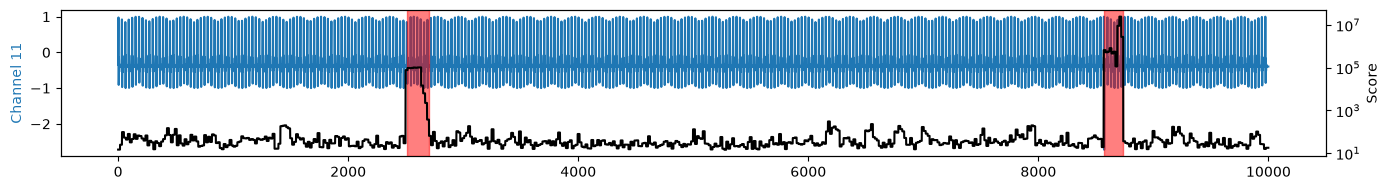

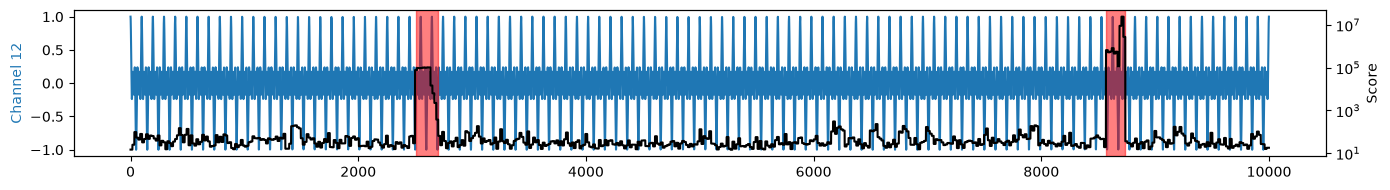

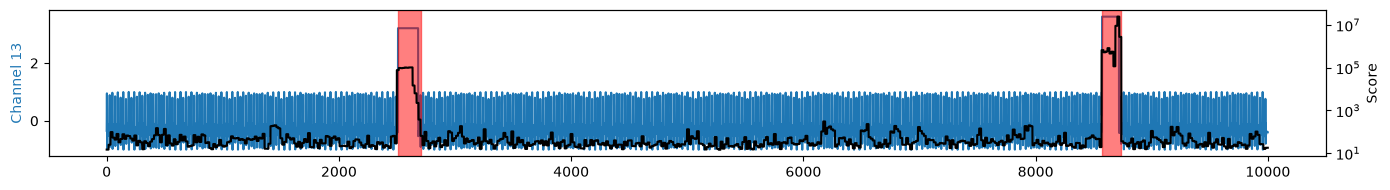

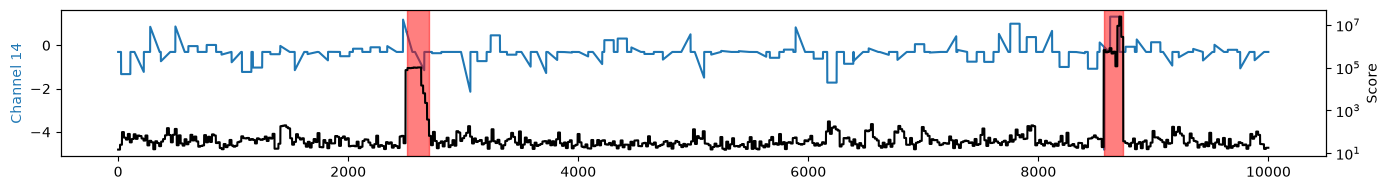

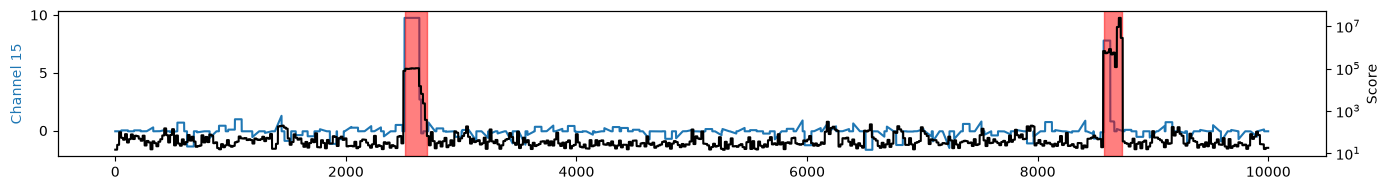

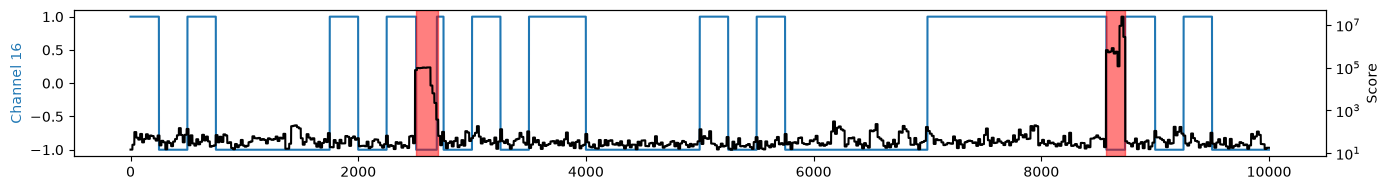

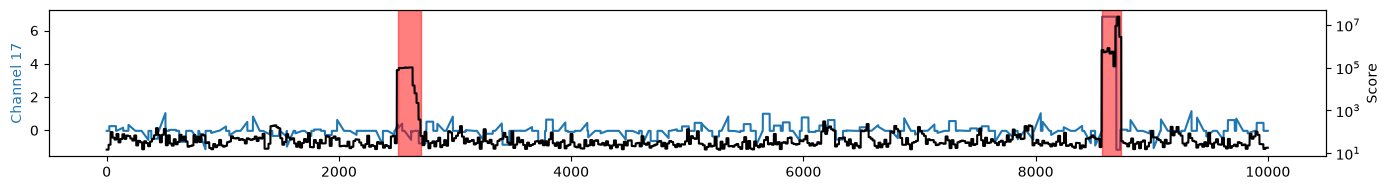

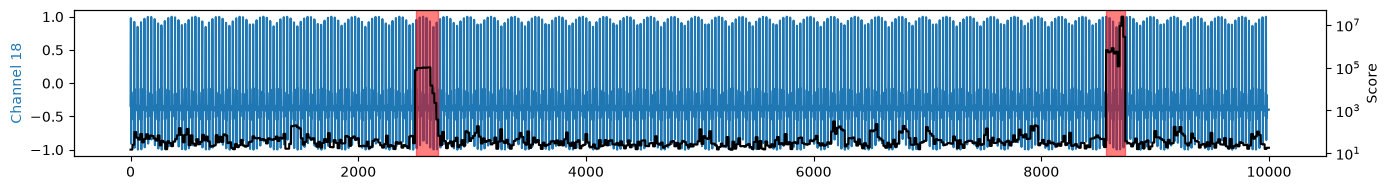

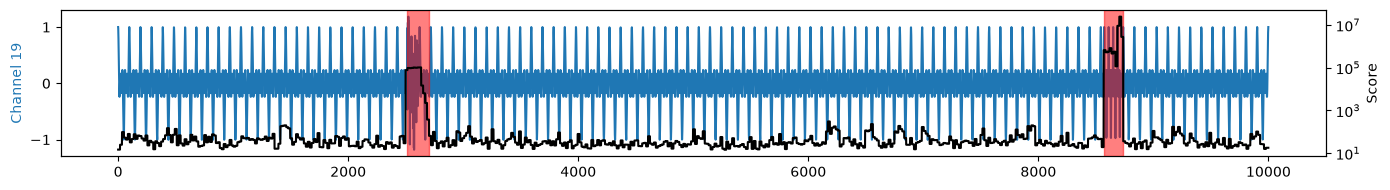

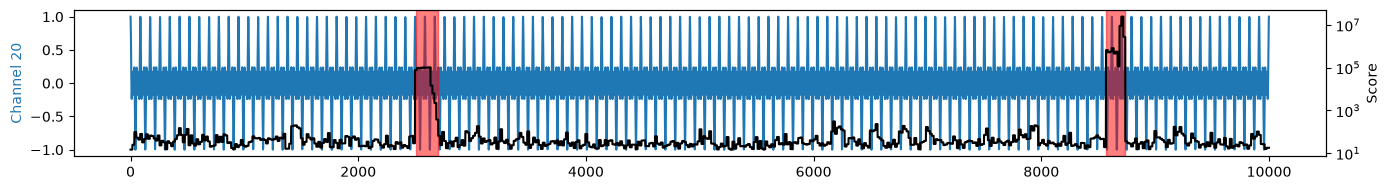

In [12]:
ts_ucf.plots.plot_scores(scaled_data_test, padded_point_scores, 1, labels_test)

## Plot the predictions with a threshold of 1000

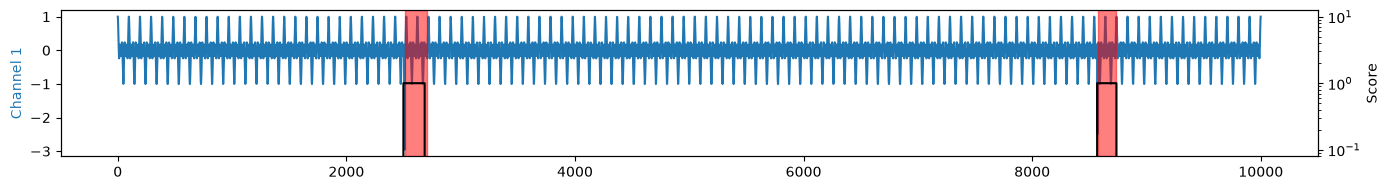

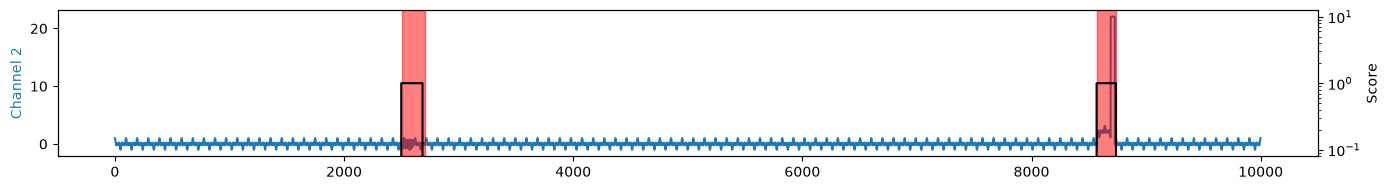

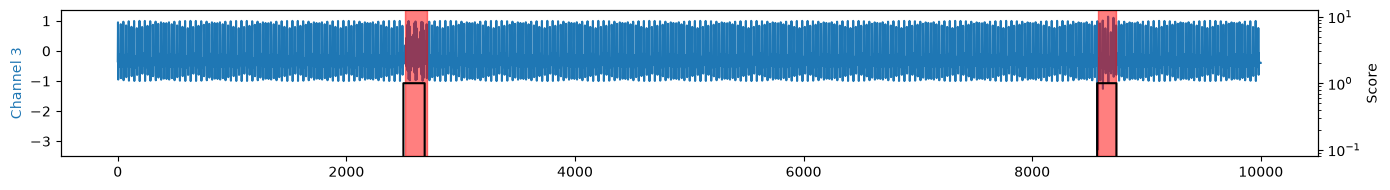

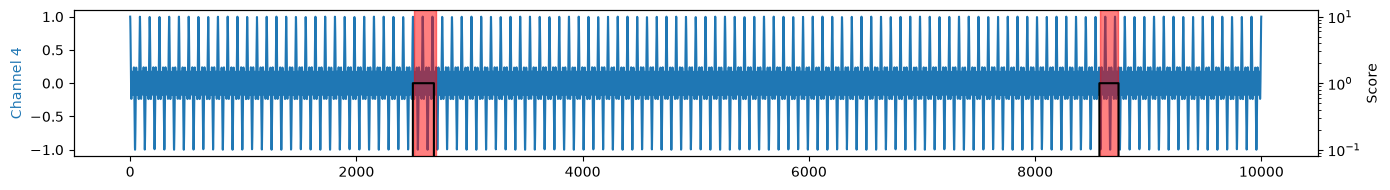

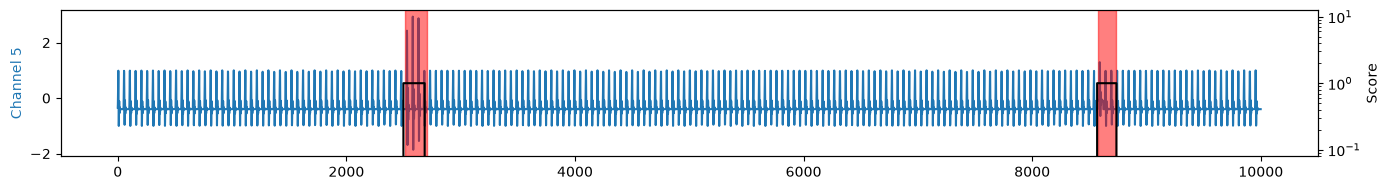

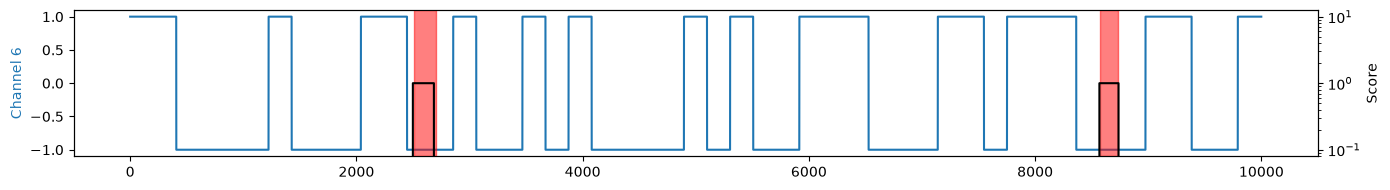

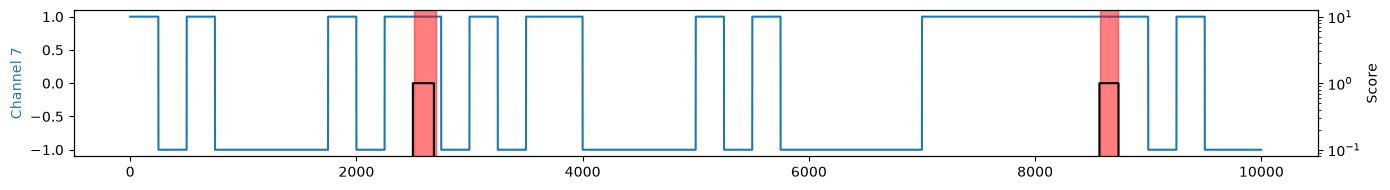

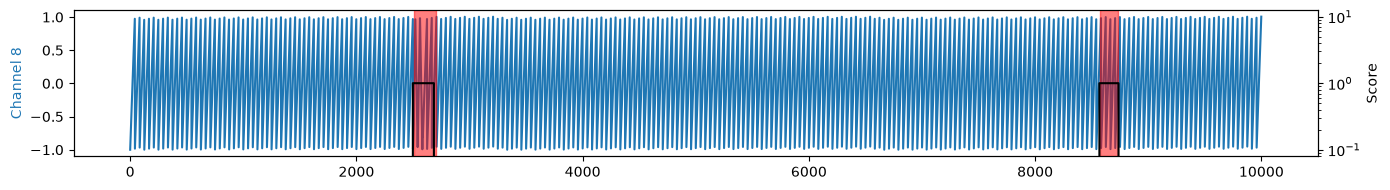

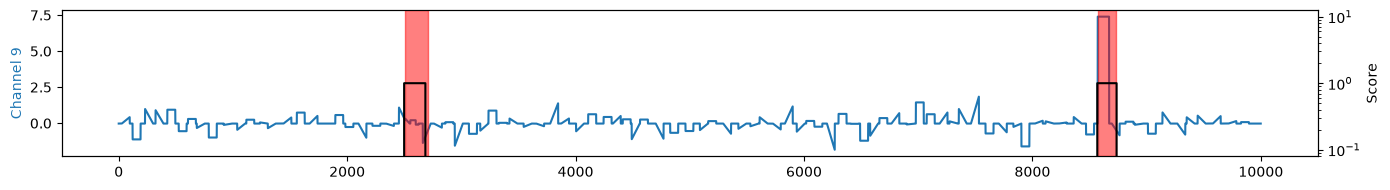

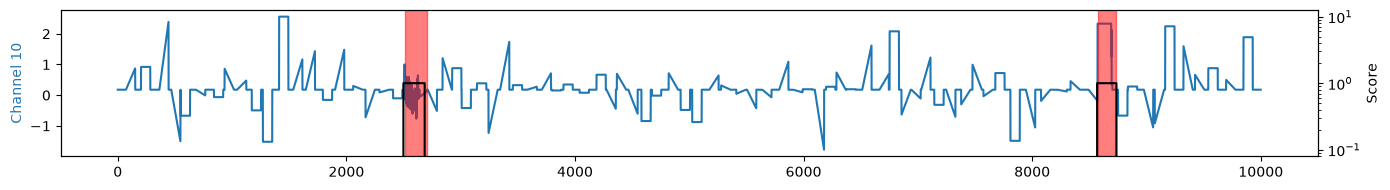

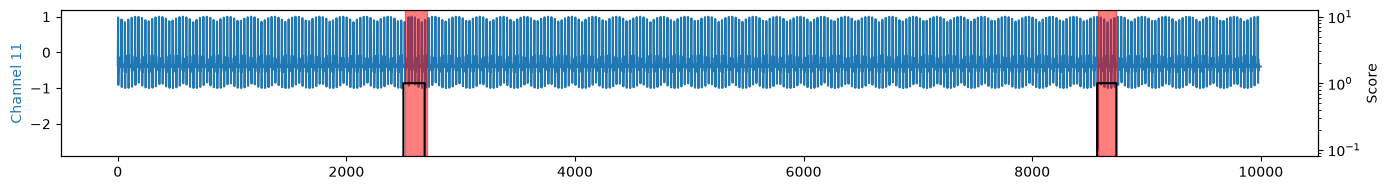

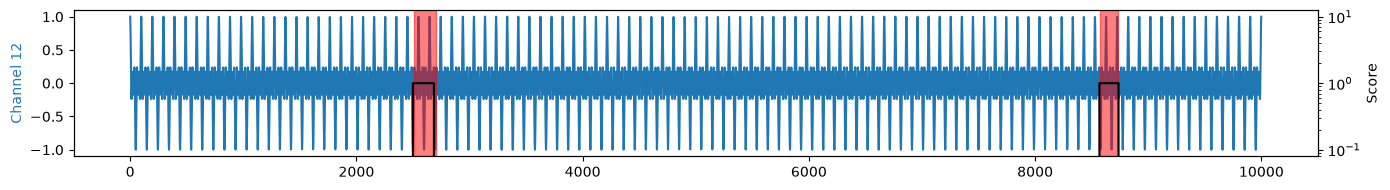

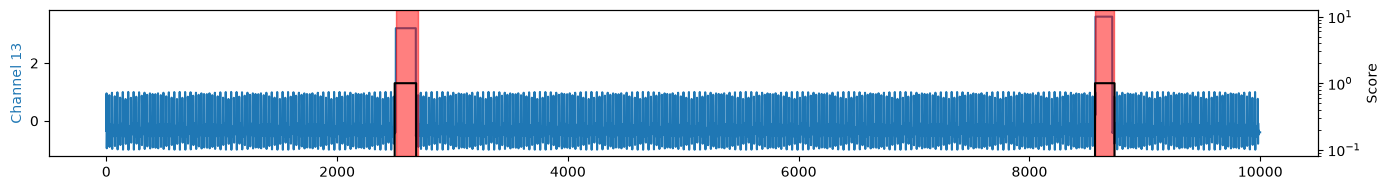

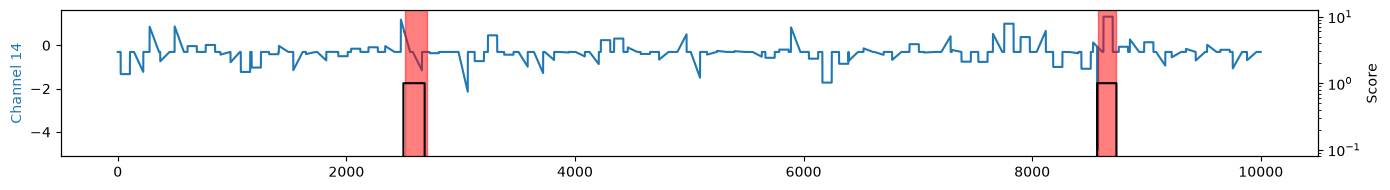

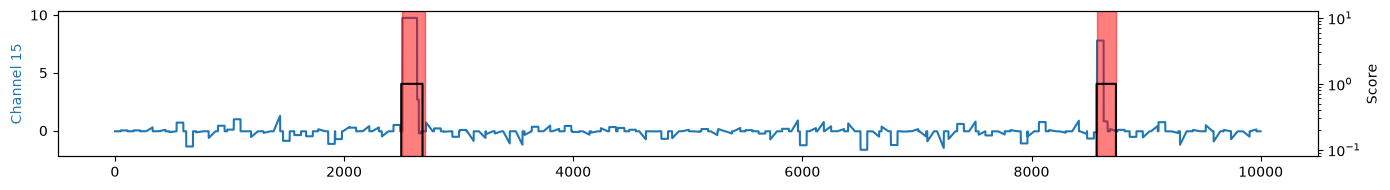

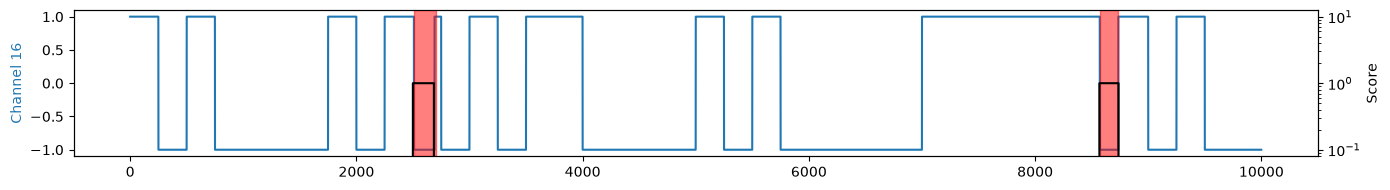

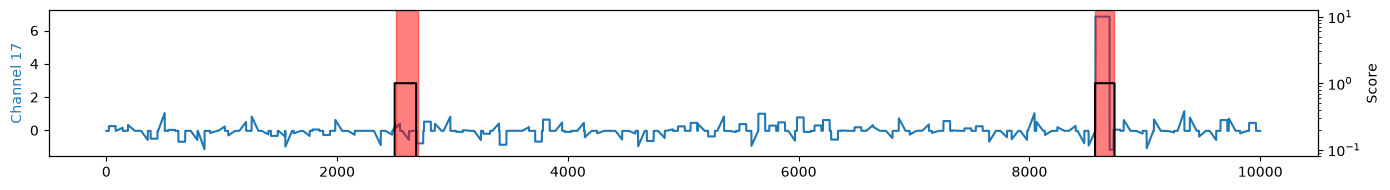

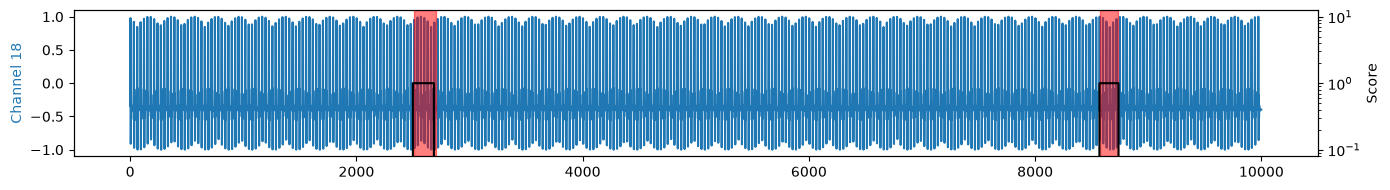

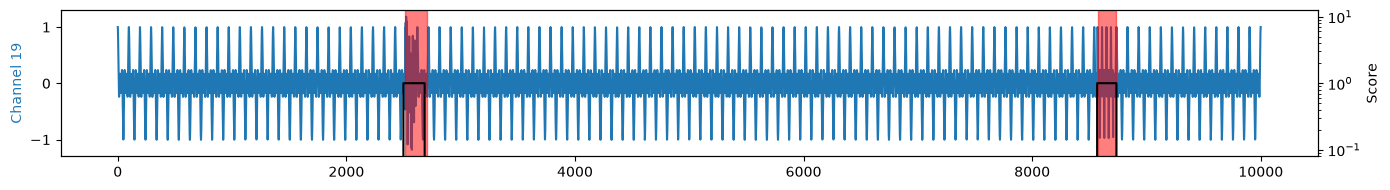

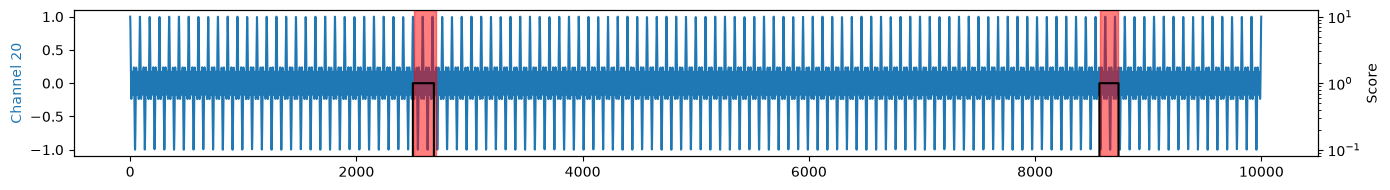

In [13]:
padded_point_pred = np.where(padded_point_scores > 1000, 1, 0)
ts_ucf.plots.plot_scores(scaled_data_test, padded_point_pred, 1, labels_test)

# Impact scores

In [14]:
impact_scores = detector.impact_scores(sigma=0.1)
impact_scores.shape # 588 windows and 20 signals

(588, 20)

In [15]:
padded_impact_scores = np.column_stack([get_padded_res(impact_scores[:, i], detector.L, len(scaled_data_test)) for i in range(impact_scores.shape[1])])
padded_impact_scores.shape

(10000, 20)

In [16]:
# Show the signal with the higher median root causes over the length of the anomaly
anos_seq = ts_ucf.plots.find_ano_events(labels_test)
for num_ano, (start, end) in enumerate(anos_seq):
    idx_ano = np.flatnonzero(padded_point_pred[start:end])
    if len(idx_ano) > 0:
        impact_scores_ano = padded_impact_scores[start:end][idx_ano]
        med_impact_scores_ano = np.median(np.unique(impact_scores_ano, axis=0), axis=0)
        sorted_impacts = np.argsort(med_impact_scores_ano)[::-1] + 1
        print(f"For ano from {start} to {end}, root causes are:")
        print({f"Channel {i}": f"{100*med_impact_scores_ano[i-1]:.2f} %" for i in sorted_impacts})

For ano from 2509 to 2705, root causes are:
{'Channel 15': '87.39 %', 'Channel 13': '9.53 %', 'Channel 5': '0.31 %', 'Channel 8': '0.29 %', 'Channel 2': '0.21 %', 'Channel 1': '0.20 %', 'Channel 19': '0.13 %', 'Channel 3': '0.13 %', 'Channel 12': '0.11 %', 'Channel 10': '0.10 %', 'Channel 14': '0.10 %', 'Channel 20': '0.10 %', 'Channel 4': '0.10 %', 'Channel 18': '0.07 %', 'Channel 11': '0.07 %', 'Channel 17': '0.05 %', 'Channel 9': '0.04 %', 'Channel 16': '0.00 %', 'Channel 6': '0.00 %', 'Channel 7': '0.00 %'}
For ano from 8572 to 8736, root causes are:
{'Channel 9': '30.71 %', 'Channel 17': '25.72 %', 'Channel 13': '6.51 %', 'Channel 2': '3.26 %', 'Channel 10': '2.77 %', 'Channel 14': '0.39 %', 'Channel 15': '0.30 %', 'Channel 1': '0.13 %', 'Channel 19': '0.09 %', 'Channel 12': '0.07 %', 'Channel 3': '0.06 %', 'Channel 5': '0.06 %', 'Channel 8': '0.05 %', 'Channel 11': '0.05 %', 'Channel 4': '0.03 %', 'Channel 20': '0.03 %', 'Channel 18': '0.02 %', 'Channel 16': '0.00 %', 'Channel 6'

## Show the impact scores of each signal

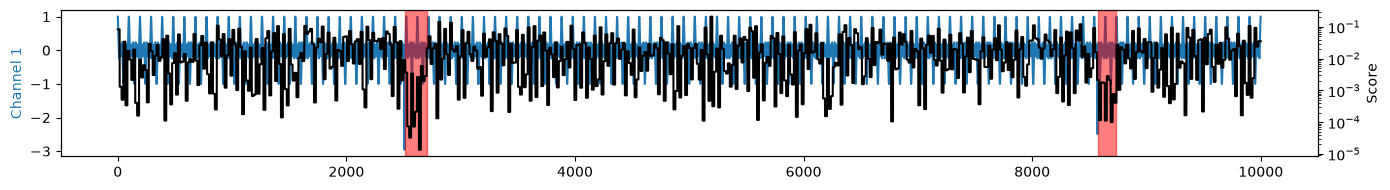

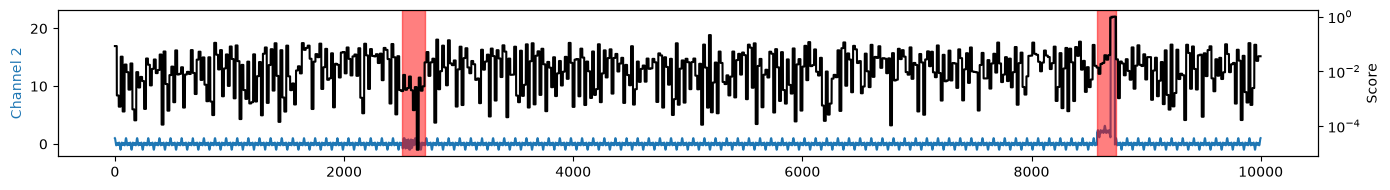

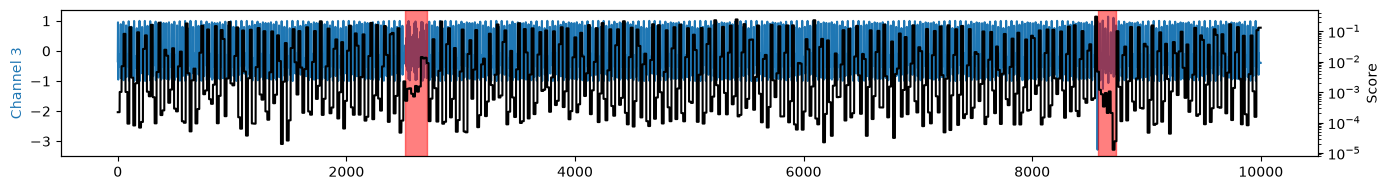

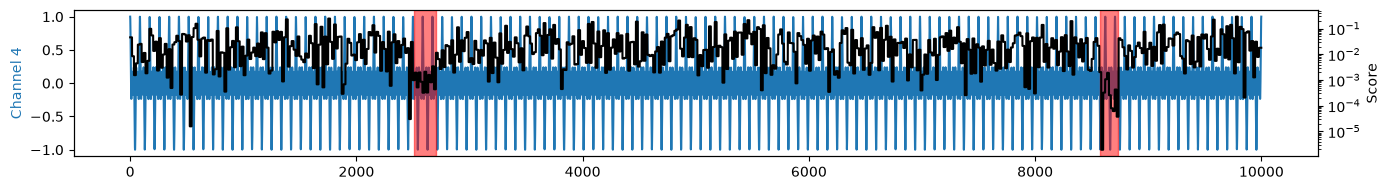

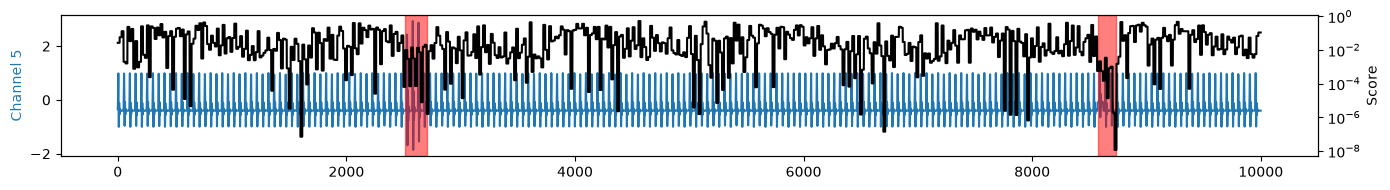

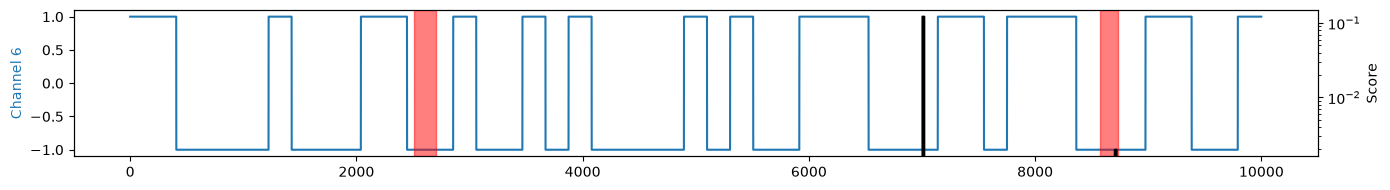

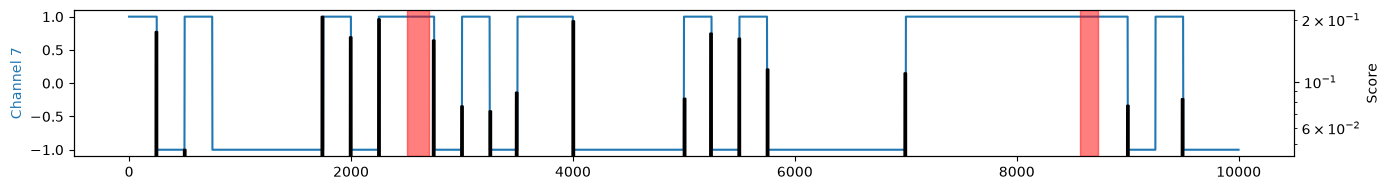

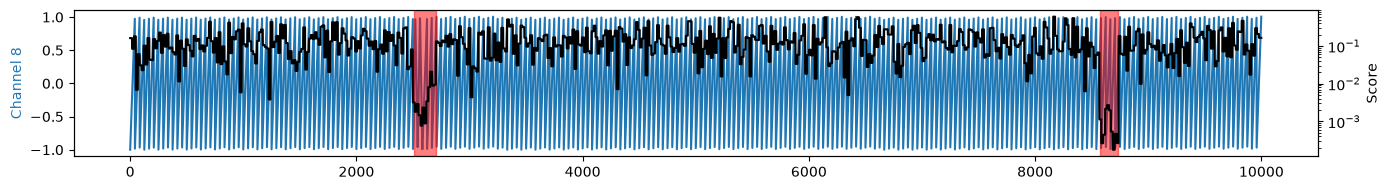

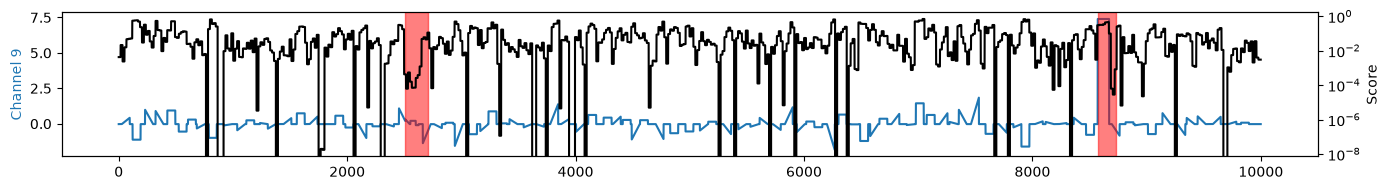

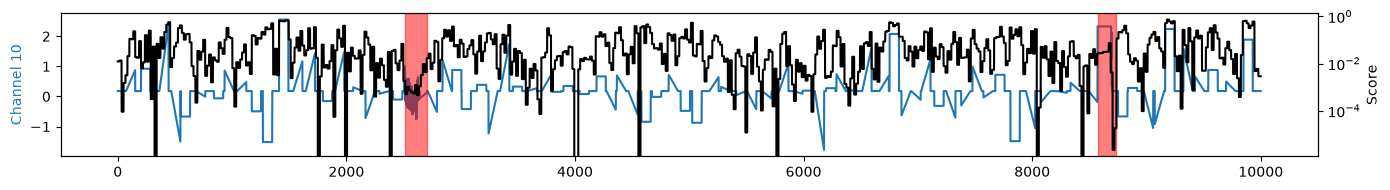

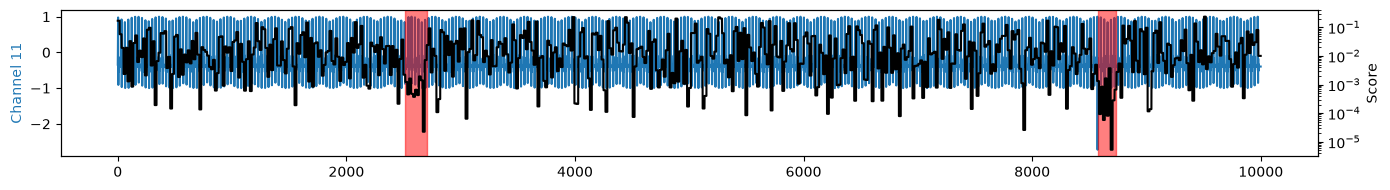

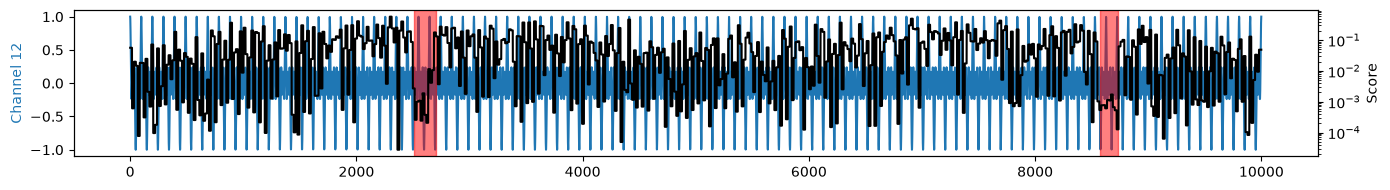

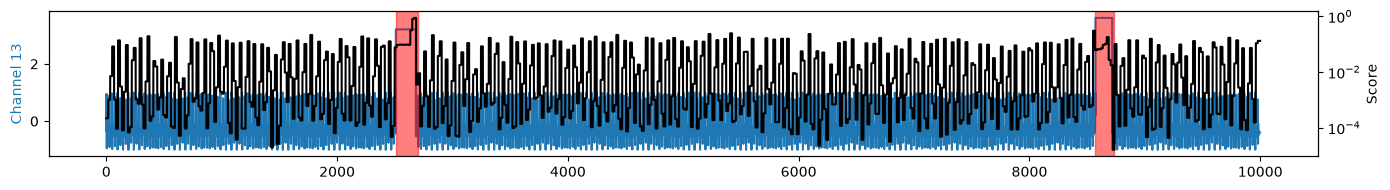

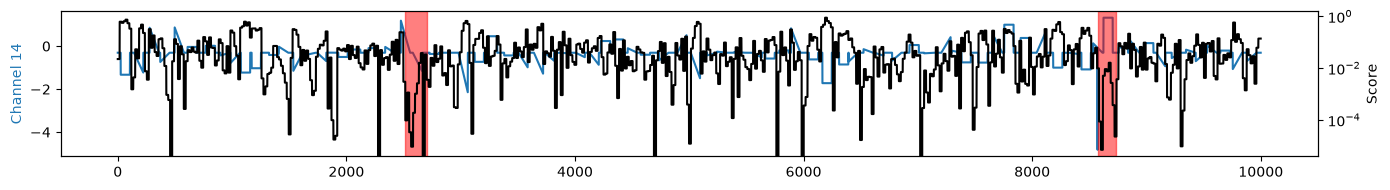

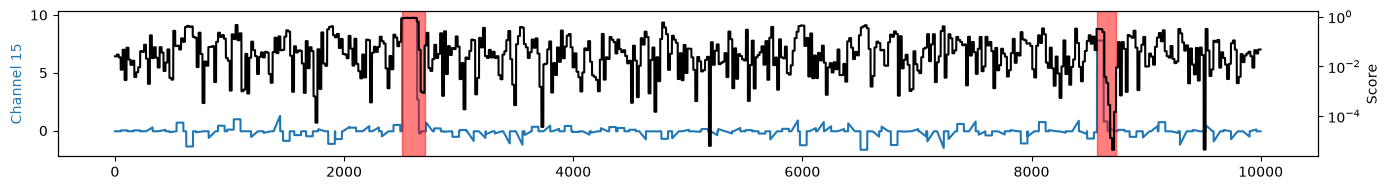

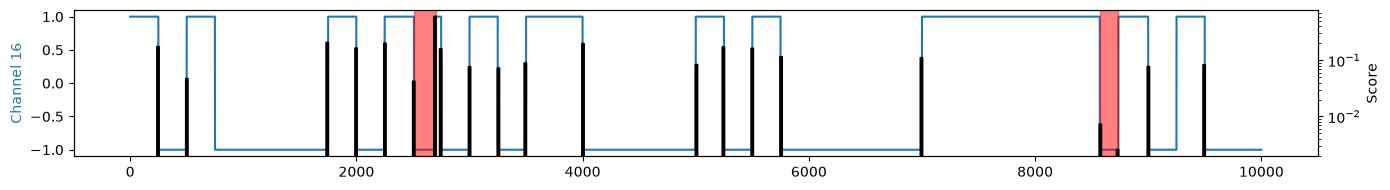

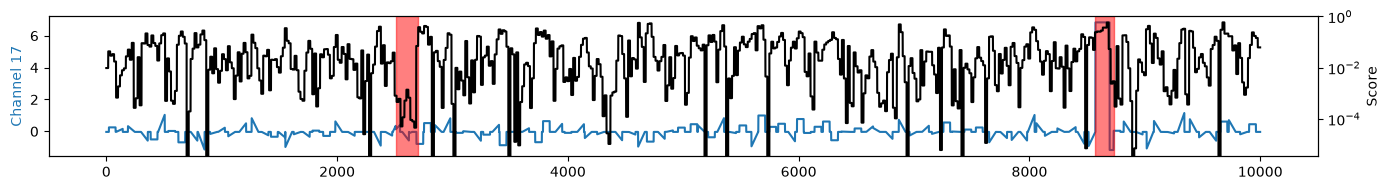

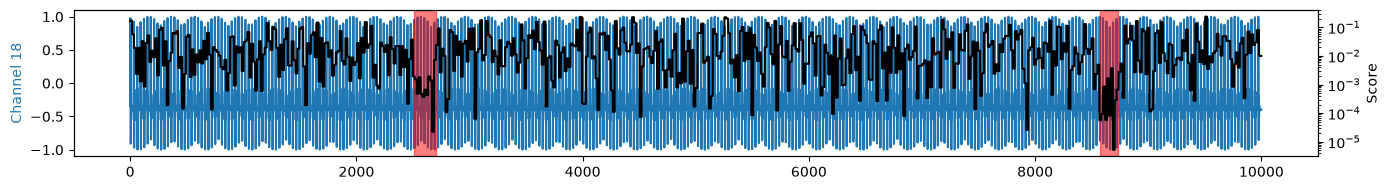

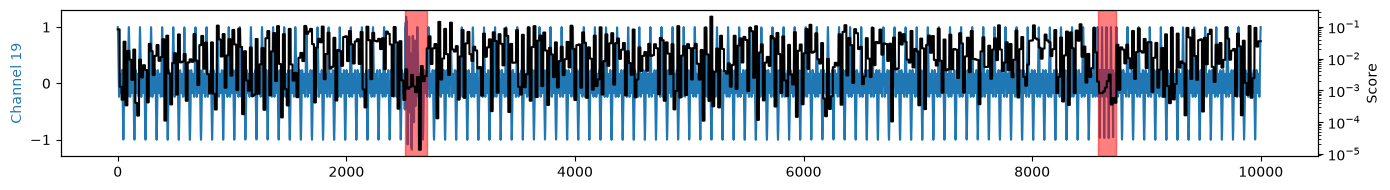

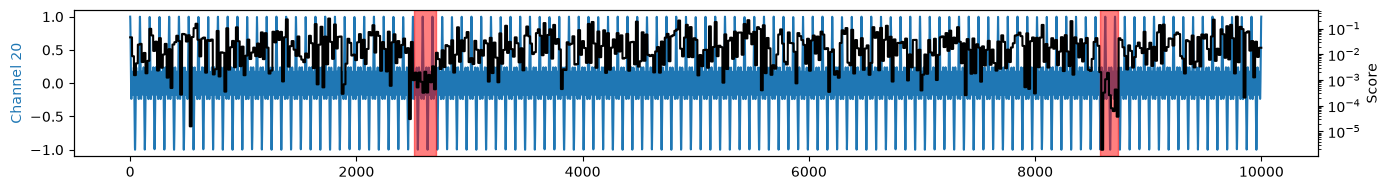

In [17]:
ts_ucf.plots.plot_scores(scaled_data_test, padded_impact_scores, 1, labels_test)